In [ ]:
from google.colab import drive
drive.mount('/content/drive')


DATA_DIR = '/content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic'

Mounted at /content/drive


In [ ]:
import os
import copy
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, Dataset
from torchvision import datasets, transforms, models
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from PIL import Image

# Check for GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


Dataset Class Distribution:
             Disease Class  Image Count
pigmented benign keratosis          462
                  melanoma          438
      basal cell carcinoma          376
                     nevus          357
   squamous cell carcinoma          181
           vascular lesion          139
         actinic keratosis          114
            dermatofibroma           95
      seborrheic keratosis           77


/tmp/ipykernel_949/3440579104.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Image Count', y='Disease Class', data=df_distribution, palette='viridis')


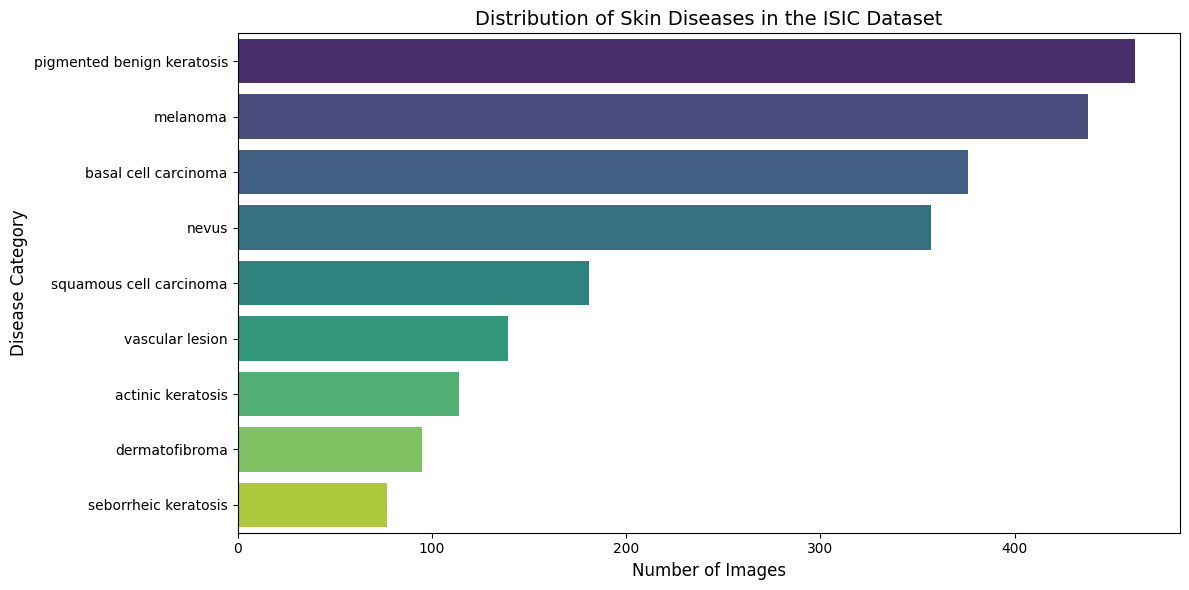

In [ ]:
from collections import Counter
import pandas as pd

# Load the base dataset without transforms to analyze raw data
base_dataset = datasets.ImageFolder(root=DATA_DIR)
class_names = base_dataset.classes

# Count occurrences of each class
class_counts = Counter(base_dataset.targets)
counts = [class_counts[i] for i in range(len(class_names))]

# Create a DataFrame for easy viewing
df_distribution = pd.DataFrame({
    'Disease Class': class_names,
    'Image Count': counts
}).sort_values(by='Image Count', ascending=False)

print("Dataset Class Distribution:")
print(df_distribution.to_string(index=False))

# Plot the distribution
plt.figure(figsize=(12, 6))
sns.barplot(x='Image Count', y='Disease Class', data=df_distribution, palette='viridis')
plt.title('Distribution of Skin Diseases in the ISIC Dataset', fontsize=14)
plt.xlabel('Number of Images', fontsize=12)
plt.ylabel('Disease Category', fontsize=12)
plt.tight_layout()
plt.show()

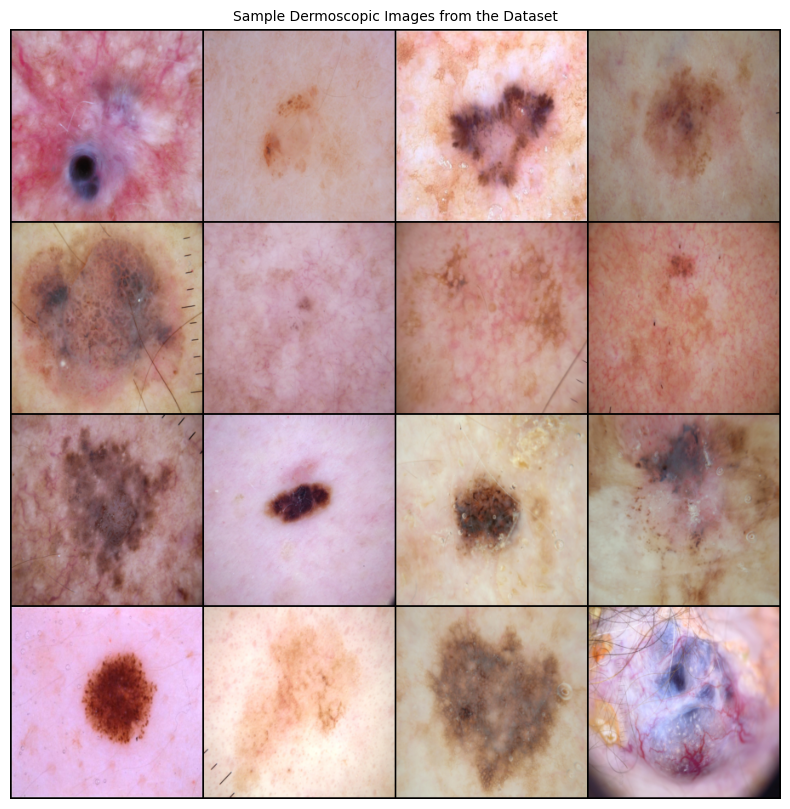

Labels for the images above:
vascular lesion, nevus, melanoma, melanoma, melanoma, basal cell carcinoma, actinic keratosis, seborrheic keratosis, pigmented benign keratosis, pigmented benign keratosis, melanoma, melanoma, nevus, melanoma, melanoma, basal cell carcinoma


In [ ]:
import torchvision

def imshow(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    # We clip values between 0 and 1 just in case
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title, fontsize=10)
    plt.axis('off')


eda_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

eda_dataset = datasets.ImageFolder(root=DATA_DIR, transform=eda_transform)
eda_loader = DataLoader(eda_dataset, batch_size=16, shuffle=True)

inputs, classes = next(iter(eda_loader))

out = torchvision.utils.make_grid(inputs, nrow=4)

plt.figure(figsize=(14, 10))
imshow(out, title="Sample Dermoscopic Images from the Dataset")
plt.show()

print("Labels for the images above:")
print(", ".join([class_names[x] for x in classes]))

Scanning 

Image Size Summary Statistics:
       Width  Height
count   2239    2239
mean     862     650
std      576     429
min      576     450
25%      600     450
50%      600     450
75%     1024     768
max     3872    2592


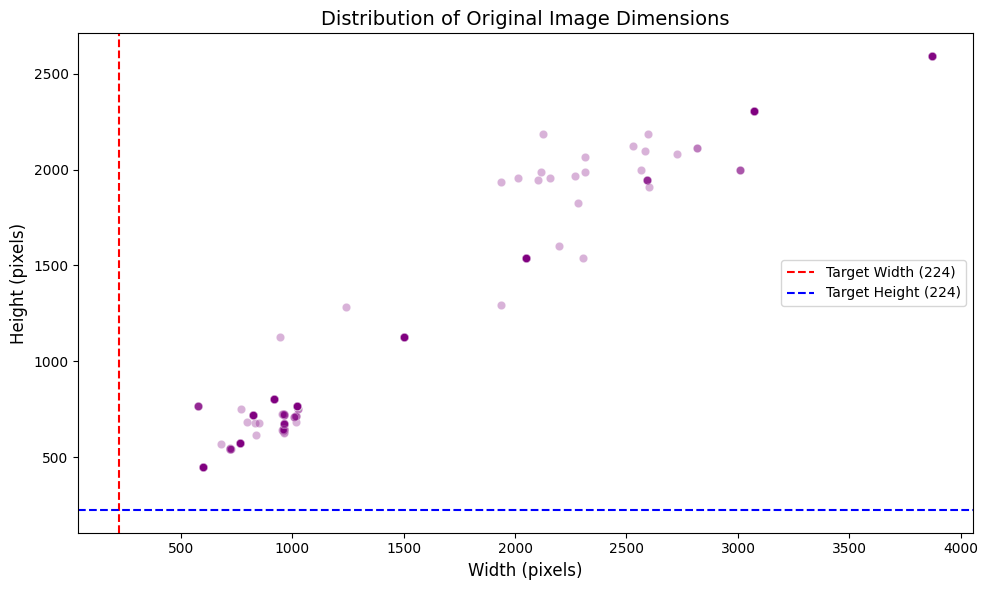

In [ ]:
widths = []
heights = []

print("Scanning ")
for path, _ in base_dataset.imgs:
    with Image.open(path) as img:
        w, h = img.size
        widths.append(w)
        heights.append(h)


df_sizes = pd.DataFrame({'Width': widths, 'Height': heights})


print("\nImage Size Summary Statistics:")
print(df_sizes.describe().astype(int))


plt.figure(figsize=(10, 6))
sns.scatterplot(x='Width', y='Height', data=df_sizes, alpha=0.3, color='purple')
plt.title('Distribution of Original Image Dimensions', fontsize=14)
plt.xlabel('Width (pixels)', fontsize=12)
plt.ylabel('Height (pixels)', fontsize=12)

# Add a marker for the ResNet target size (224x224)
plt.axvline(x=224, color='red', linestyle='--', label='Target Width (224)')
plt.axhline(y=224, color='blue', linestyle='--', label='Target Height (224)')
plt.legend()
plt.tight_layout()
plt.show()

Sampling images for pixel intensity analysis...


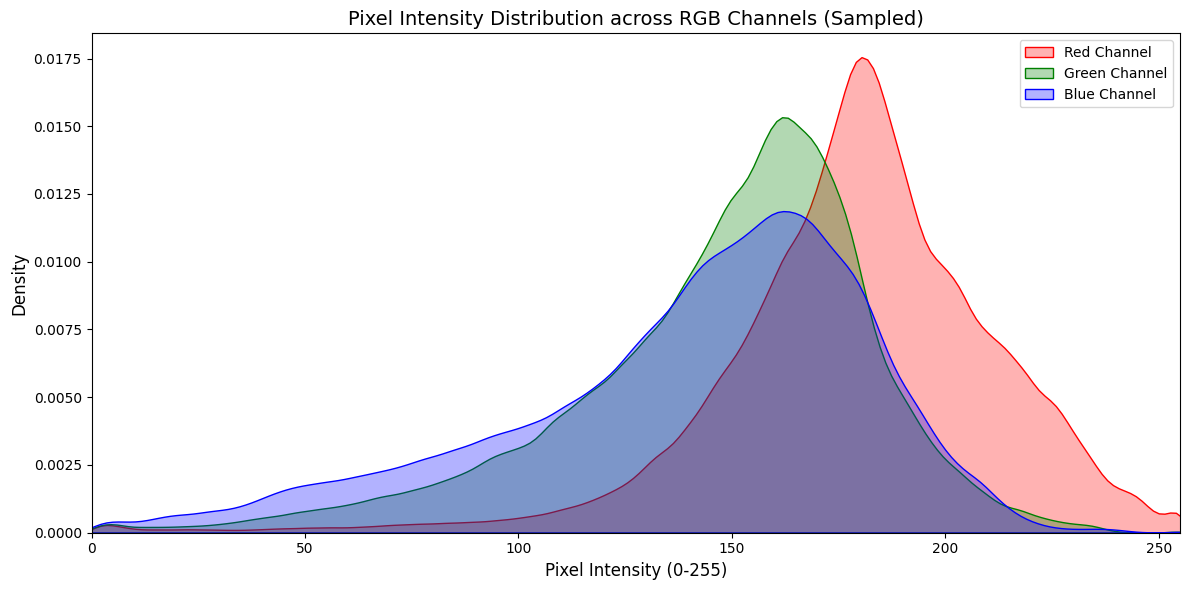

In [ ]:
import random

print("Sampling images for pixel intensity analysis...")

r_values, g_values, b_values = [], [], []

sample_indices = random.sample(range(len(base_dataset)), 150)

for idx in sample_indices:
    path, _ = base_dataset.imgs[idx]
    with Image.open(path) as img:
        img_arr = np.array(img.convert('RGB'))

        r_values.extend(img_arr[:, :, 0].flatten()[::100])
        g_values.extend(img_arr[:, :, 1].flatten()[::100])
        b_values.extend(img_arr[:, :, 2].flatten()[::100])

plt.figure(figsize=(12, 6))

sns.kdeplot(r_values, color='red', label='Red Channel', fill=True, alpha=0.3)
sns.kdeplot(g_values, color='green', label='Green Channel', fill=True, alpha=0.3)
sns.kdeplot(b_values, color='blue', label='Blue Channel', fill=True, alpha=0.3)

plt.title('Pixel Intensity Distribution across RGB Channels (Sampled)', fontsize=14)
plt.xlabel('Pixel Intensity (0-255)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.xlim(0, 255)
plt.legend()
plt.tight_layout()
plt.show()

del r_values, g_values, b_values

In [ ]:
from collections import Counter as Ctr

corrupt_files = []
mode_counts = Ctr()

print(f"Checking {len(base_dataset.imgs)} images...")
for path, _ in base_dataset.imgs:
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            mode_counts[img.mode] += 1
    except Exception as e:
        corrupt_files.append((path, str(e)))

print(f"\nCorrupt/unreadable files: {len(corrupt_files)}")
for p, err in corrupt_files[:10]:
    print(f"  {p} -> {err}")

print(f"\nImage mode distribution: {dict(mode_counts)}")

Checking 2239 images...

Corrupt/unreadable files: 0

Image mode distribution: {'RGB': 2239}


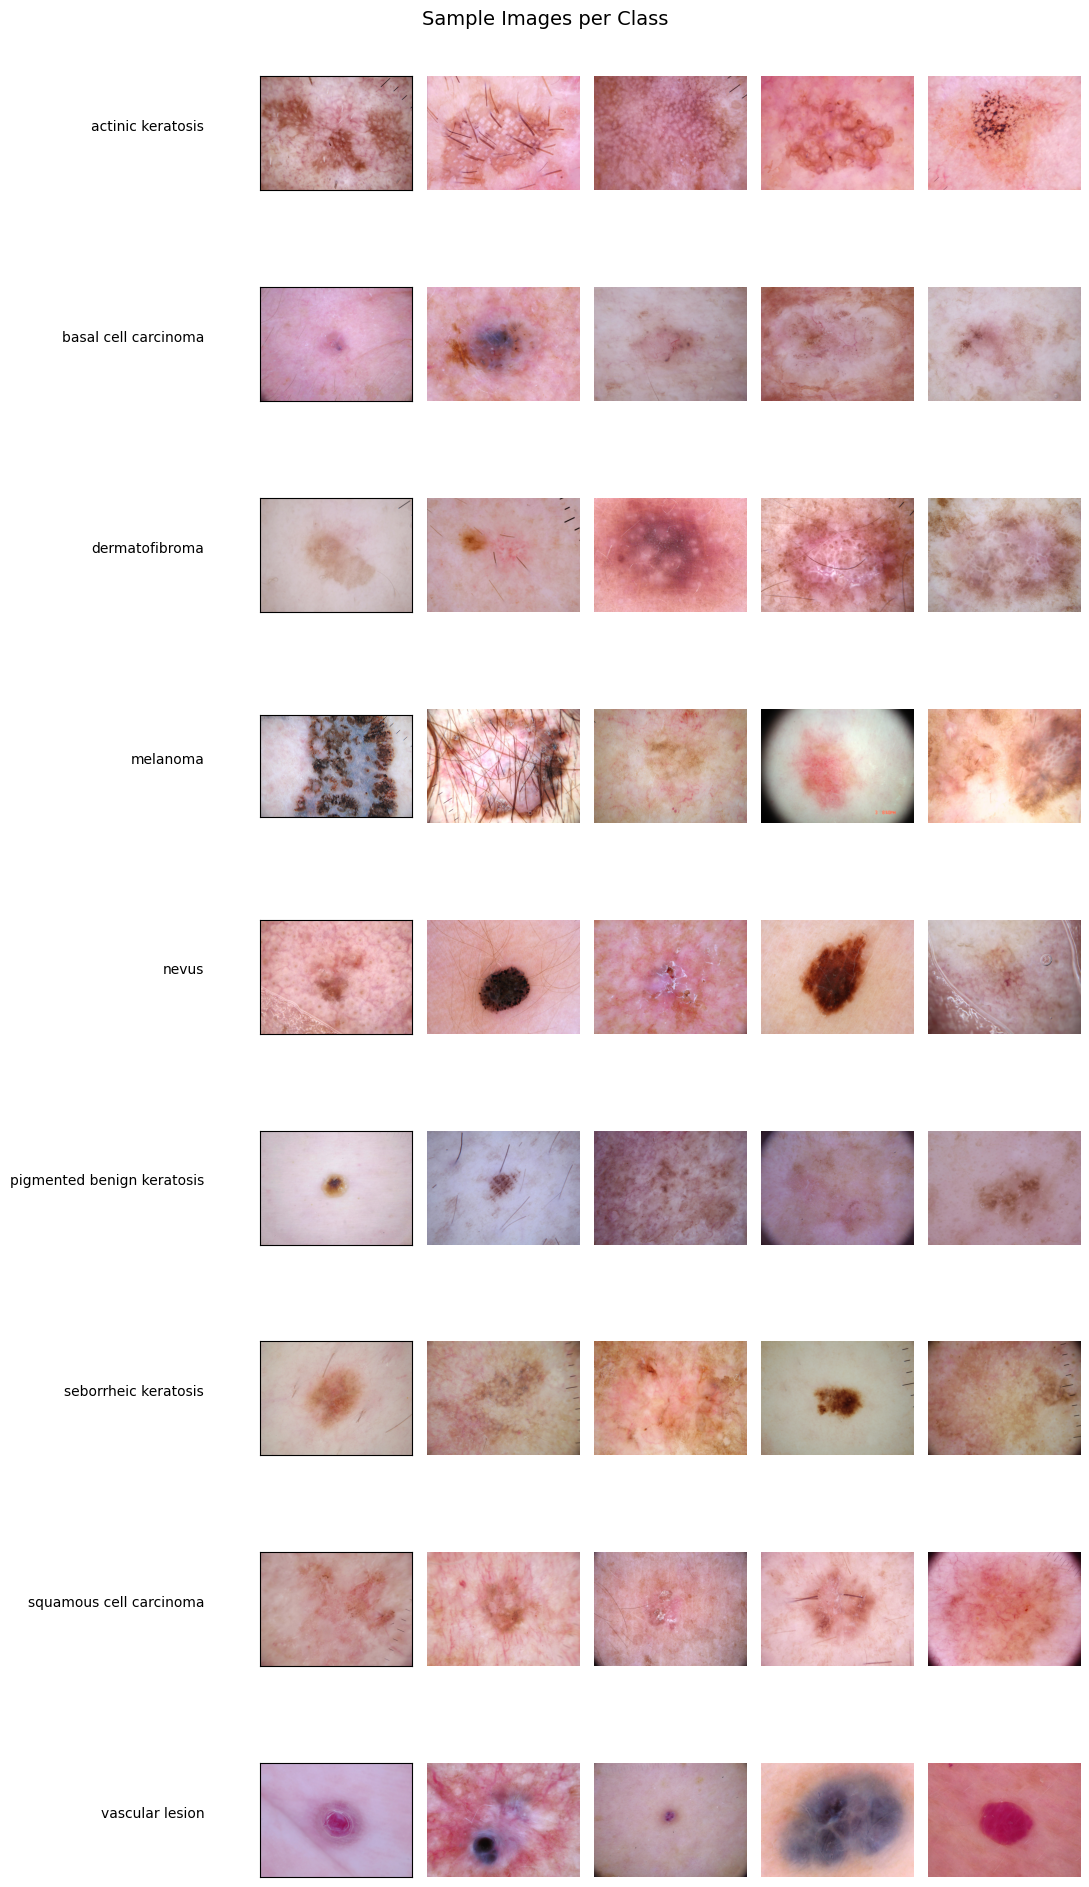

In [ ]:
n_per_class = 5
fig, axes = plt.subplots(len(class_names), n_per_class, figsize=(n_per_class * 2.2, len(class_names) * 2.2))

for row, cls in enumerate(class_names):
    cls_idx = class_names.index(cls)
    cls_paths = [p for p, label in base_dataset.imgs if label == cls_idx]
    sample_paths = random.sample(cls_paths, min(n_per_class, len(cls_paths)))

    for col in range(n_per_class):
        ax = axes[row, col]
        if col < len(sample_paths):
            img = Image.open(sample_paths[col]).convert('RGB')
            ax.imshow(img)
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(cls, fontsize=10, rotation=0, labelpad=40, ha='right')
            ax.axis('on')
            ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Sample Images per Class', fontsize=14)
plt.tight_layout()
plt.show()

                     Class     Mean R     Mean G     Mean B
         actinic keratosis 199.258601 144.062982 150.129539
      basal cell carcinoma 194.029167 156.147636 165.108616
            dermatofibroma 198.261778 150.752338 158.824455
                  melanoma 186.245583 152.285150 135.505935
                     nevus 183.317946 148.306078 143.358366
pigmented benign keratosis 178.045677 136.425814 144.741435
      seborrheic keratosis 186.294039 156.874826 140.473145
   squamous cell carcinoma 202.070918 154.643496 159.245480
           vascular lesion 198.939163 151.279233 163.592692


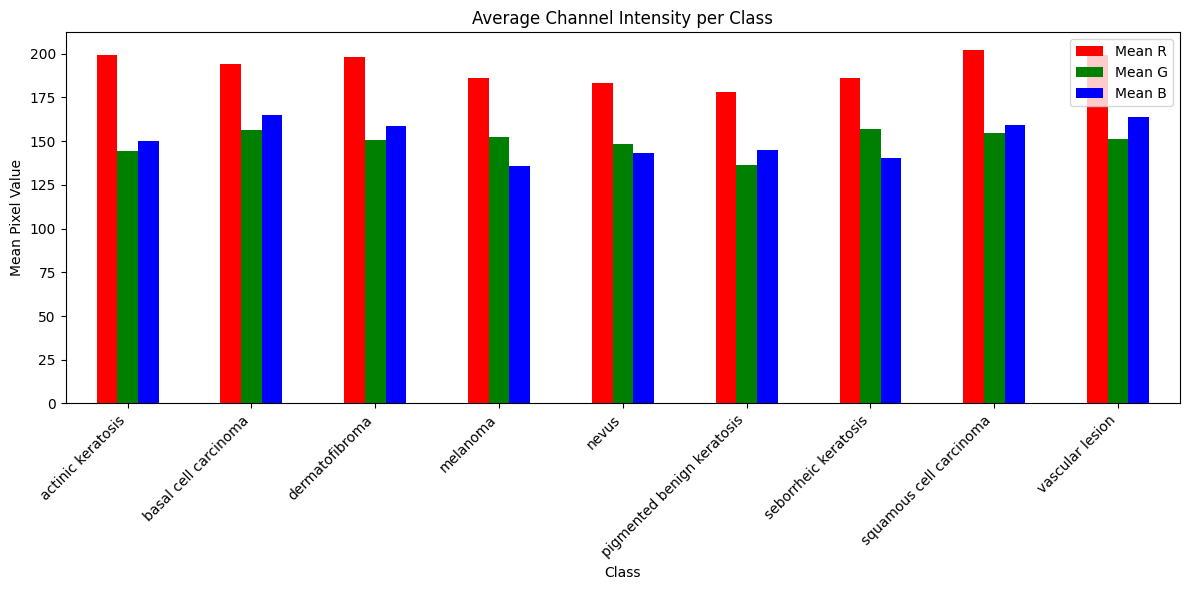

In [ ]:
class_color_means = []

for cls_idx, cls in enumerate(class_names):
    cls_paths = [p for p, label in base_dataset.imgs if label == cls_idx]
    sample_paths = random.sample(cls_paths, min(50, len(cls_paths)))

    r_means, g_means, b_means = [], [], []
    for path in sample_paths:
        arr = np.array(Image.open(path).convert('RGB'))
        r_means.append(arr[:, :, 0].mean())
        g_means.append(arr[:, :, 1].mean())
        b_means.append(arr[:, :, 2].mean())

    class_color_means.append({
        'Class': cls,
        'Mean R': np.mean(r_means),
        'Mean G': np.mean(g_means),
        'Mean B': np.mean(b_means)
    })

df_colors = pd.DataFrame(class_color_means)
print(df_colors.to_string(index=False))

df_colors.set_index('Class')[['Mean R', 'Mean G', 'Mean B']].plot(
    kind='bar', figsize=(12, 6), color=['red', 'green', 'blue']
)
plt.title('Average Channel Intensity per Class')
plt.ylabel('Mean Pixel Value')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
import hashlib

hashes = {}
duplicates = []

for path, label in base_dataset.imgs:
    with open(path, 'rb') as f:
        file_hash = hashlib.md5(f.read()).hexdigest()
    if file_hash in hashes:
        duplicates.append((path, hashes[file_hash]))
    else:
        hashes[file_hash] = path

print(f"Exact duplicate files found: {len(duplicates)}")
for dup, original in duplicates[:10]:
    print(f"  {dup}\n    duplicate of -> {original}")

Exact duplicate files found: 139
  /content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic/melanoma/ISIC_0000280.jpg
    duplicate of -> /content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic/melanoma/ISIC_0000279.jpg
  /content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic/nevus/ISIC_0000512.jpg
    duplicate of -> /content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic/nevus/ISIC_0000477.jpg
  /content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic/nevus/ISIC_0025780.jpg
    duplicate of -> /content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic/actinic keratosis/ISIC_0025780.jpg
  /content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic/nevus/ISIC_0025803.jpg
    duplicate of -> /content/drive/MyDrive/LAB/Skin cancer ISI

In [ ]:
from sklearn.model_selection import train_test_split

labels = base_dataset.targets
indices = list(range(len(labels)))

train_idx, temp_idx = train_test_split(indices, test_size=0.3, stratify=labels, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5,
                                       stratify=[labels[i] for i in temp_idx], random_state=42)

for name, idx_set in [('Train', train_idx), ('Val', val_idx), ('Test', test_idx)]:
    split_labels = [labels[i] for i in idx_set]
    dist = Counter(split_labels)
    print(f"\n{name} ({len(idx_set)} images):")
    for i, cls in enumerate(class_names):
        pct = 100 * dist[i] / len(idx_set)
        print(f"  {cls}: {dist[i]} ({pct:.1f}%)")


Train (1567 images):
  actinic keratosis: 80 (5.1%)
  basal cell carcinoma: 263 (16.8%)
  dermatofibroma: 66 (4.2%)
  melanoma: 307 (19.6%)
  nevus: 250 (16.0%)
  pigmented benign keratosis: 323 (20.6%)
  seborrheic keratosis: 54 (3.4%)
  squamous cell carcinoma: 127 (8.1%)
  vascular lesion: 97 (6.2%)

Val (336 images):
  actinic keratosis: 17 (5.1%)
  basal cell carcinoma: 57 (17.0%)
  dermatofibroma: 14 (4.2%)
  melanoma: 66 (19.6%)
  nevus: 53 (15.8%)
  pigmented benign keratosis: 69 (20.5%)
  seborrheic keratosis: 12 (3.6%)
  squamous cell carcinoma: 27 (8.0%)
  vascular lesion: 21 (6.2%)

Test (336 images):
  actinic keratosis: 17 (5.1%)
  basal cell carcinoma: 56 (16.7%)
  dermatofibroma: 15 (4.5%)
  melanoma: 65 (19.3%)
  nevus: 54 (16.1%)
  pigmented benign keratosis: 70 (20.8%)
  seborrheic keratosis: 11 (3.3%)
  squamous cell carcinoma: 27 (8.0%)
  vascular lesion: 21 (6.2%)


In [ ]:
corrupt_paths = set(p for p, _ in corrupt_files)
duplicate_paths = set(dup for dup, orig in duplicates)
exclude_paths = corrupt_paths | duplicate_paths

valid_indices = [i for i, (path, _) in enumerate(base_dataset.imgs) if path not in exclude_paths]

print(f"Total images: {len(base_dataset.imgs)}")
print(f"Excluded (corrupt/duplicate): {len(exclude_paths)}")
print(f"Remaining valid images: {len(valid_indices)}")

Total images: 2239
Excluded (corrupt/duplicate): 139
Remaining valid images: 2100


In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

In [ ]:
train_dataset_full = datasets.ImageFolder(root=DATA_DIR, transform=train_transform)
eval_dataset_full = datasets.ImageFolder(root=DATA_DIR, transform=eval_transform)

valid_labels = [base_dataset.targets[i] for i in valid_indices]


train_val_idx, test_idx = train_test_split(valid_indices, test_size=0.15, stratify=valid_labels, random_state=42)


train_val_labels = [base_dataset.targets[i] for i in train_val_idx]


train_idx, val_idx = train_test_split(train_val_idx, test_size=(0.15 / 0.85), stratify=train_val_labels, random_state=42)

from torch.utils.data import Subset
train_data = Subset(train_dataset_full, train_idx)
val_data = Subset(eval_dataset_full, val_idx)
test_data = Subset(eval_dataset_full, test_idx)

print(f"Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}")

Train: 1470, Val: 315, Test: 315


In [ ]:
from torch.utils.data import WeightedRandomSampler

train_labels = [base_dataset.targets[i] for i in train_idx]
class_sample_counts = np.array([train_labels.count(i) for i in range(len(class_names))])
class_weights = 1.0 / class_sample_counts
sample_weights = np.array([class_weights[label] for label in train_labels])

sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models
import copy
import time


num_classes = len(class_names)


model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)


model = model.to(device)


criterion = nn.CrossEntropyLoss()


optimizer = optim.Adam(model.parameters(), lr=0.001)


scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


In [ ]:
f

<_io.BufferedReader name='/content/drive/MyDrive/LAB/Skin cancer ISIC The International Skin Imaging Collaboration/isic/vascular lesion/ISIC_0034214.jpg'>

In [ ]:
def train_model_short(model, criterion, optimizer, num_epochs=15):
    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader

            running_loss, running_corrects = 0.0, 0

            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)
            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f}, Acc: {epoch_acc:.4f}')

    return model

# Execute the training
trained_model = train_model_short(model, criterion, optimizer, num_epochs=15)

Epoch 1/15
Train Loss: 1.3658, Acc: 0.5252
Val Loss: 2.1180, Acc: 0.4571
Epoch 2/15
Train Loss: 1.0531, Acc: 0.6354
Val Loss: 2.0366, Acc: 0.4095
Epoch 3/15
Train Loss: 0.9588, Acc: 0.6524
Val Loss: 1.2054, Acc: 0.5556
Epoch 4/15
Train Loss: 0.8768, Acc: 0.6932
Val Loss: 1.1493, Acc: 0.5937
Epoch 5/15
Train Loss: 0.8288, Acc: 0.7150
Val Loss: 1.2536, Acc: 0.5683
Epoch 6/15
Train Loss: 0.7793, Acc: 0.7252
Val Loss: 1.1957, Acc: 0.5587
Epoch 7/15
Train Loss: 0.7588, Acc: 0.7361
Val Loss: 1.0421, Acc: 0.6286
Epoch 8/15
Train Loss: 0.7021, Acc: 0.7490
Val Loss: 0.9815, Acc: 0.6476
Epoch 9/15
Train Loss: 0.6903, Acc: 0.7476
Val Loss: 1.1267, Acc: 0.6286
Epoch 10/15
Train Loss: 0.7276, Acc: 0.7415
Val Loss: 1.3457, Acc: 0.5492
Epoch 11/15
Train Loss: 0.6695, Acc: 0.7701
Val Loss: 1.5630, Acc: 0.4381
Epoch 12/15
Train Loss: 0.6337, Acc: 0.7810
Val Loss: 1.1690, Acc: 0.6476
Epoch 13/15
Train Loss: 0.6124, Acc: 0.7966
Val Loss: 1.5919, Acc: 0.5175
Epoch 14/15
Train Loss: 0.7074, Acc: 0.7633
Val

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

def evaluate_model(model, dataloader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_preds)

# Evaluate on the test dataset
y_true, y_pred = evaluate_model(trained_model, test_loader)

# Calculate and display metrics
print("=== Classification Report ===")
# Added labels parameter to prevent error when classes are missing from test split
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

accuracy = accuracy_score(y_true, y_pred)
print(f"Overall Test Accuracy: {accuracy * 100:.2f}%")


=== Classification Report ===
                            precision    recall  f1-score   support

         actinic keratosis       0.50      0.82      0.62        17
      basal cell carcinoma       0.77      0.84      0.81        57
            dermatofibroma       0.45      0.93      0.60        14
                  melanoma       1.00      0.42      0.60        66
                     nevus       0.64      0.64      0.64        44
pigmented benign keratosis       0.59      0.68      0.63        69
      seborrheic keratosis       0.00      0.00      0.00         0
   squamous cell carcinoma       0.35      0.26      0.30        27
           vascular lesion       0.79      0.90      0.84        21

                  accuracy                           0.65       315
                 macro avg       0.57      0.61      0.56       315
              weighted avg       0.70      0.65      0.64       315

Overall Test Accuracy: 64.76%
